# Hackathon – Dataset C (COVID vaccine) · Notebook 09 of 09
## Explainable AI (SHAP, odds ratios, permutation importance) and conclusions

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


In [2]:
import shap
from sklearn.inspection import permutation_importance
from IPython.display import Markdown, display

BEST_PREP = load_json('best_prep.json')
TUNED = build_tuned_models(BEST_PREP, load_json('tuned_params.json'))
FINAL = load_csv('final_selection.csv', index_col=0)                 # notebook 08
exp_costs = load_csv('expected_test_costs.csv', index_col=0).iloc[:, 0]
hold_table = load_csv('holdout_table.csv', index_col=0)

def slug(text):
    return ''.join(ch if ch.isalnum() else '_' for ch in text).strip('_').replace('__', '_').lower()

# Models re-trained on ALL labelled data (as used for the submissions) ...
cat_final = clone(TUNED['CatBoost']).fit(X_all, y_all)
lr_final = clone(TUNED['Logistic Regression']).fit(X_all, y_all)
# ... and models trained on the development set only, for permutation importance on the unseen hold-out set
HOLD_MODELS = {m: clone(TUNED[m]).fit(X_dev, y_dev)
               for m in ['Logistic Regression', 'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']}
print('models ready')

/Users/mathujans/Downloads/hackathon_datasetC_9_notebooks/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


models ready


## 9. Explainable AI
We explain the models in three complementary ways:
1. **SHAP values** for CatBoost (exact TreeSHAP, computed on the *original* features thanks to native categorical handling) – global importance,
   direction of effects, and single-person explanations.
2. **Odds ratios** of the logistic regression – a transparent, global "rule of thumb" model.
3. **Permutation importance on the hold-out set** for several models – both the classic version (increase in log-loss) and a **cost-based version**:
   *how many dollars per resident does the town lose if this feature is scrambled?*

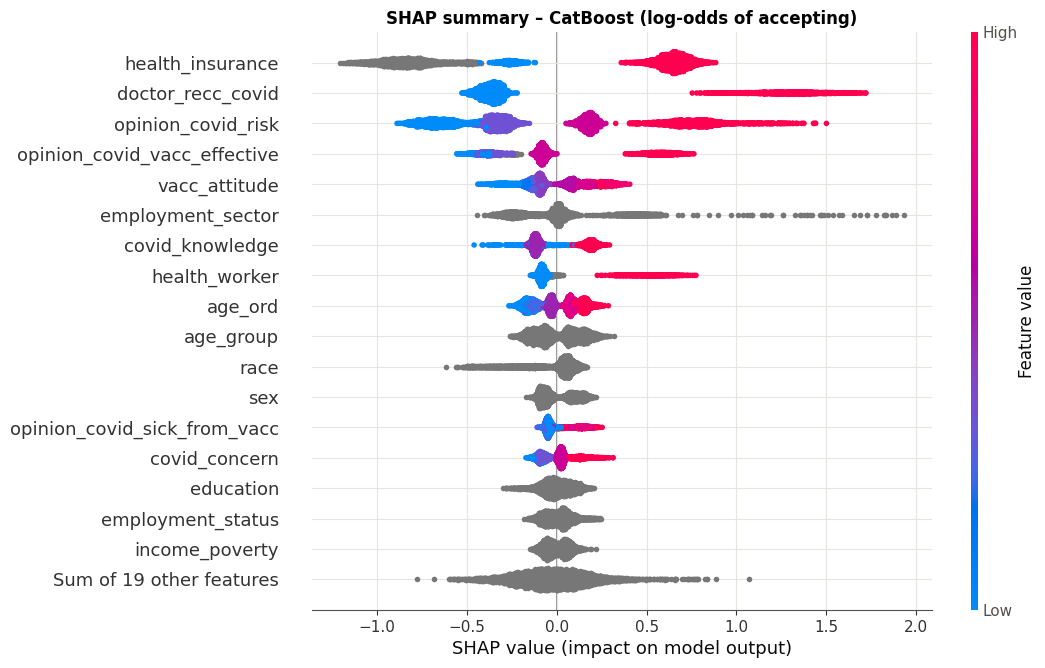

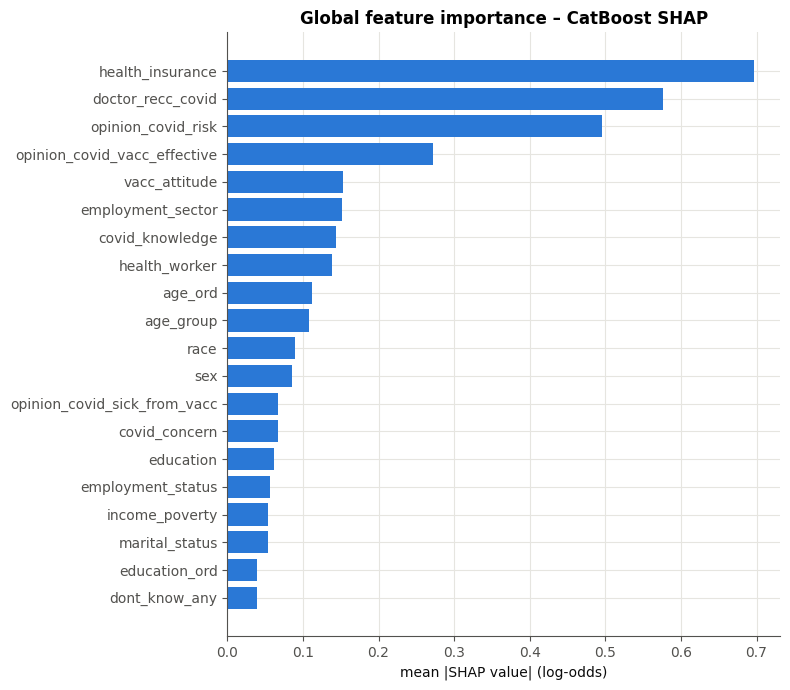

In [3]:
# SHAP values of CatBoost re-trained on all labelled data (it is one of the ensemble members)
X_explain = cat_final.named_steps['clean'].transform(X_all)
sv, base_value, Xf = cat_final.named_steps['clf'].shap_values(X_explain)
explanation = shap.Explanation(values=sv, base_values=np.full(len(sv), base_value), data=Xf.to_numpy(),
                               feature_names=list(Xf.columns))

# beeswarm colours points by feature value -> give it numbers (nominal categories have no order, so they are shown grey)
data_num = Xf.copy()
data_num[CATEGORICAL] = np.nan
explanation_num = shap.Explanation(values=sv, base_values=np.full(len(sv), base_value),
                                   data=data_num.astype(float).to_numpy(), feature_names=list(Xf.columns))
plt.figure()
warnings.filterwarnings('ignore', category=RuntimeWarning)       # all-NaN colour values for nominal features
shap.plots.beeswarm(explanation_num, max_display=18, show=False, plot_size=(10, 7.5))
plt.title('SHAP summary – CatBoost (log-odds of accepting)'); savefig('09_shap_beeswarm'); plt.show()

shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=Xf.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(shap_imp.index[-20:], shap_imp.values[-20:], color=BLUE)
ax.set_xlabel('mean |SHAP value| (log-odds)'); ax.set_title('Global feature importance – CatBoost SHAP')
plt.tight_layout(); savefig('09_shap_bar'); plt.show()

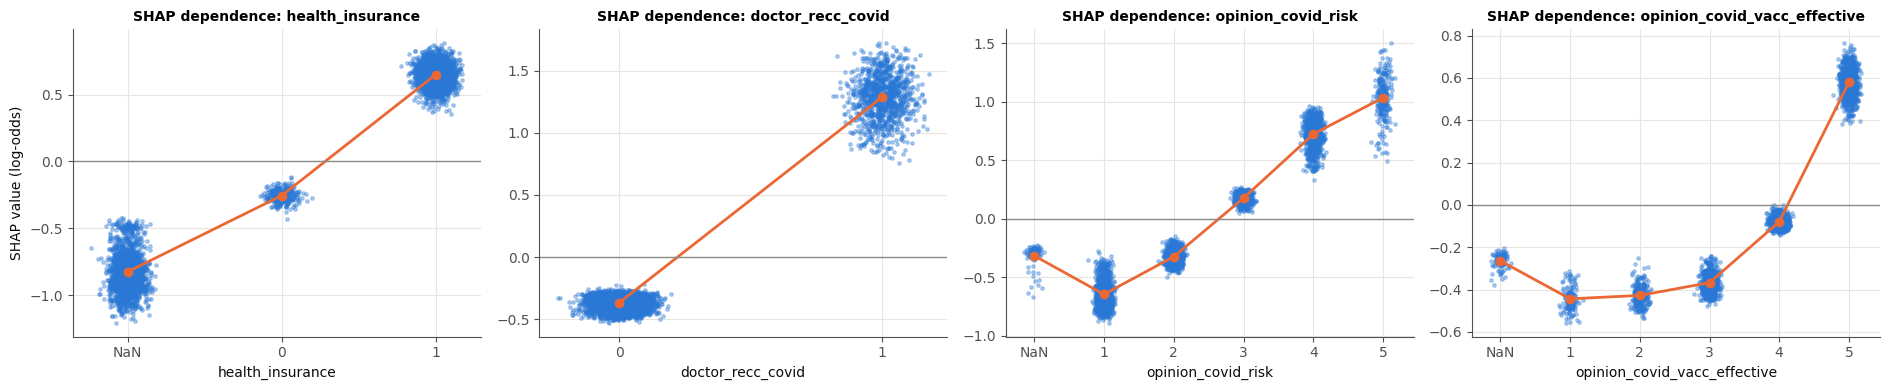

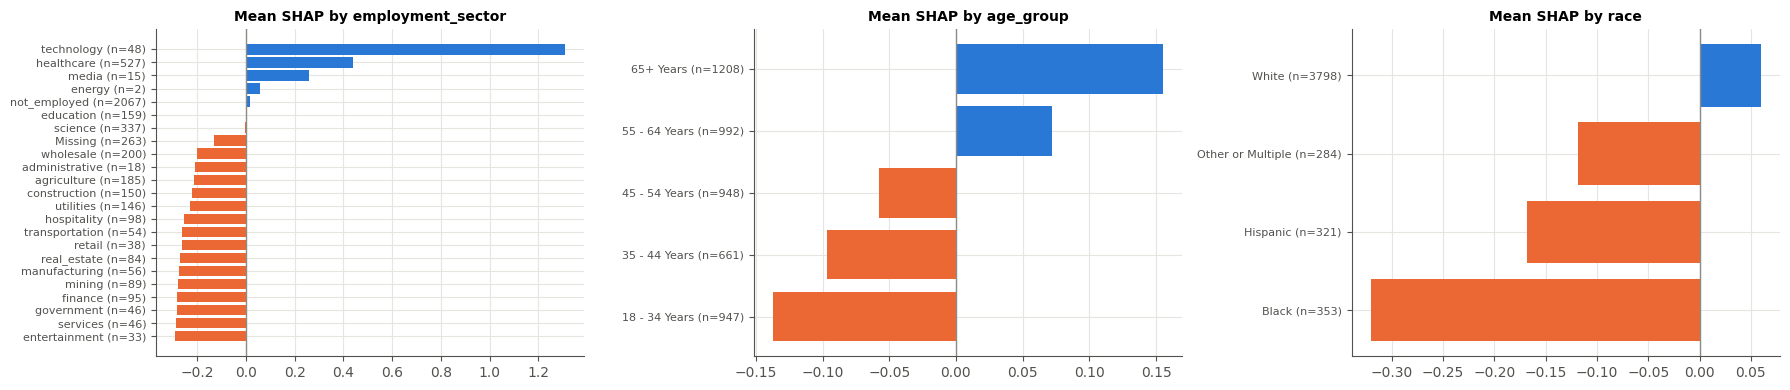

In [4]:
# How do the top features shape the prediction? (SHAP dependence)
top_num = [c for c in shap_imp.index[::-1] if c not in CATEGORICAL][:4]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, c in zip(axes, top_num):
    j = list(Xf.columns).index(c)
    x = pd.to_numeric(Xf[c], errors='coerce').to_numpy()
    has_nan = np.isnan(x).any()
    if has_nan:                                   # show missing answers as their own column at the left
        x = np.where(np.isnan(x), np.nanmin(x) - 1, x)
    jitter = np.random.default_rng(0).normal(0, 0.06, len(x))
    ax.scatter(x + jitter, sv[:, j], s=6, alpha=0.35, color=BLUE)
    means = pd.Series(sv[:, j]).groupby(x).mean()
    ax.plot(means.index, means.values, color=ORANGE, lw=2, marker='o')
    ax.axhline(0, color=GREY, lw=1); ax.set_xlabel(c); ax.set_title(f'SHAP dependence: {c}', fontsize=10)
    ticks = np.unique(x)
    ax.set_xticks(ticks, ['NaN' if (has_nan and t == ticks.min()) else f'{t:g}' for t in ticks])
axes[0].set_ylabel('SHAP value (log-odds)')
plt.tight_layout(); savefig('09_shap_dependence'); plt.show()

# Categorical features: average SHAP per category
cat_top = [c for c in shap_imp.index[::-1] if c in CATEGORICAL][:3]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, cat_top):
    j = list(Xf.columns).index(c)
    g = pd.Series(sv[:, j]).groupby(Xf[c].to_numpy()).agg(['mean', 'size']).sort_values('mean')
    ax.barh([f'{i} (n={n})' for i, n in zip(g.index, g['size'])], g['mean'], color=[ORANGE if v < 0 else BLUE for v in g['mean']])
    ax.axvline(0, color=GREY, lw=1); ax.set_title(f'Mean SHAP by {c}', fontsize=10); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); savefig('09_shap_categorical'); plt.show()

young, low risk: P(accept)=0.31  P(hosp|unvacc)=1.4%  personal threshold=0.76  -> do not send   (truth: accepted)


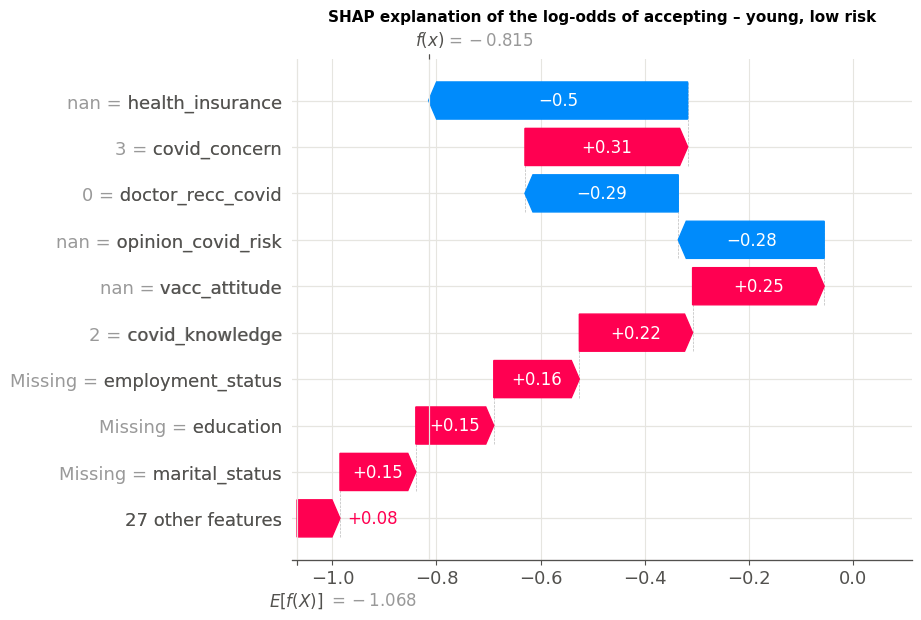

older, high risk: P(accept)=0.35  P(hosp|unvacc)=31.5%  personal threshold=0.12  -> SEND   (truth: refused)


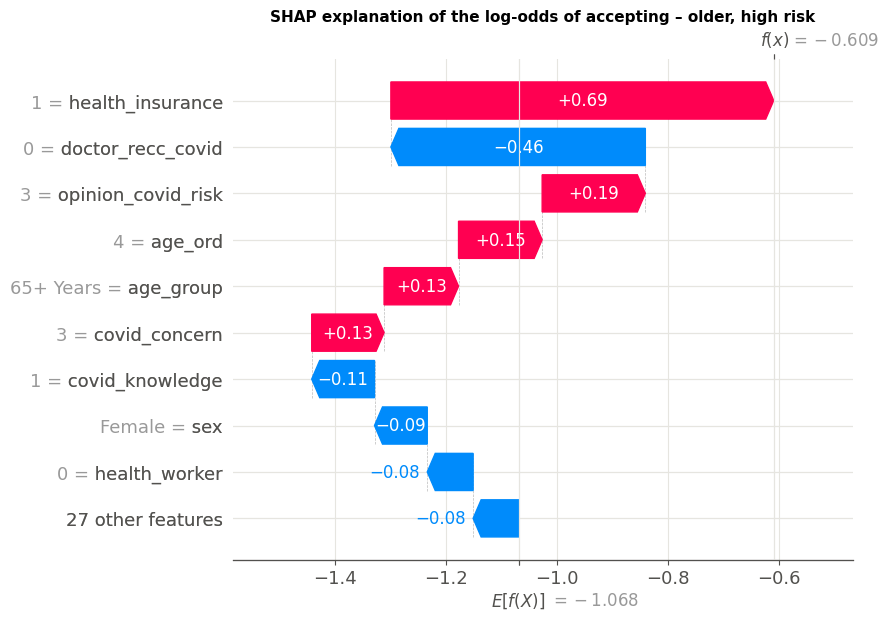

In [5]:
# Local explanations: why do two people with SIMILAR acceptance probability get DIFFERENT decisions?
q_all = cat_final.predict_proba(X_all)[:, 1]
thr_all = MAIN.personal_threshold(X_all)
p_all = MAIN.p_unvacc(X_all)
mid = (q_all > 0.3) & (q_all < 0.4)
young = np.where(mid & (X_all['age_group'] == '18 - 34 Years').to_numpy() & (p_all < 0.03))[0][0]
old = np.where(mid & (X_all['age_group'] == '65+ Years').to_numpy() & (p_all > 0.15))[0][0]

for idx, label in [(young, 'young, low risk'), (old, 'older, high risk')]:
    print(f"{label}: P(accept)={q_all[idx]:.2f}  P(hosp|unvacc)={p_all[idx]:.1%}  personal threshold={thr_all[idx]:.2f}"
          f"  -> {'SEND' if q_all[idx] >= thr_all[idx] else 'do not send'}   (truth: {'accepted' if y_all.iloc[idx] else 'refused'})")
    plt.figure()
    shap.plots.waterfall(explanation[idx], max_display=10, show=False)
    plt.title(f'SHAP explanation of the log-odds of accepting – {label}', fontsize=11); savefig(f'09_waterfall_{slug(label)}'); plt.show()

The two residents above have almost the same predicted acceptance probability, but the older one has a much higher hospitalisation risk, so the cost-optimal
rule posts them a dose while the young person gets none (if they turn out to want it, paying \$1 500 cash is cheaper on average than wasting doses on
people who probably refuse). **The final decision = acceptance model (explained by SHAP) × hospitalisation-risk model (explained by the table in Section 2).**

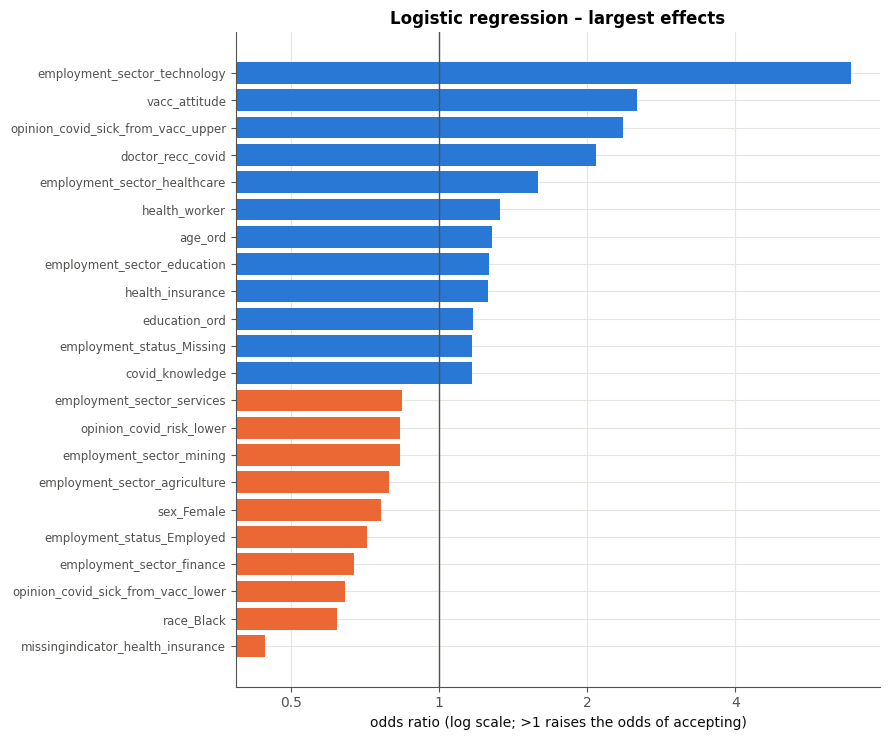

Features set exactly to 0 by the elastic-net penalty: 31 of 92


In [6]:
# Logistic regression: odds ratios (standardised inputs -> effect of +1 standard deviation / of a category)
names = lr_final.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(lr_final.named_steps['clf'].coef_[0], index=[n.split('__', 1)[1] for n in names])
top = coefs[coefs.abs().sort_values(ascending=False).index[:22]].sort_values()

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(top.index, np.exp(top.values), color=[ORANGE if v < 0 else BLUE for v in top.values], left=0)
ax.axvline(1, color=INK2, lw=1)
ax.set_xscale('log')
ax.xaxis.set_major_locator(mpl.ticker.FixedLocator([0.25, 0.5, 1, 2, 4, 8]))
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlabel('odds ratio (log scale; >1 raises the odds of accepting)')
ax.set_title('Logistic regression – largest effects'); ax.tick_params(axis='y', labelsize=8.5)
plt.tight_layout(); savefig('09_lr_odds_ratios'); plt.show()
print('Features set exactly to 0 by the elastic-net penalty:', int((coefs == 0).sum()), 'of', len(coefs))

permutation importance done in 18s


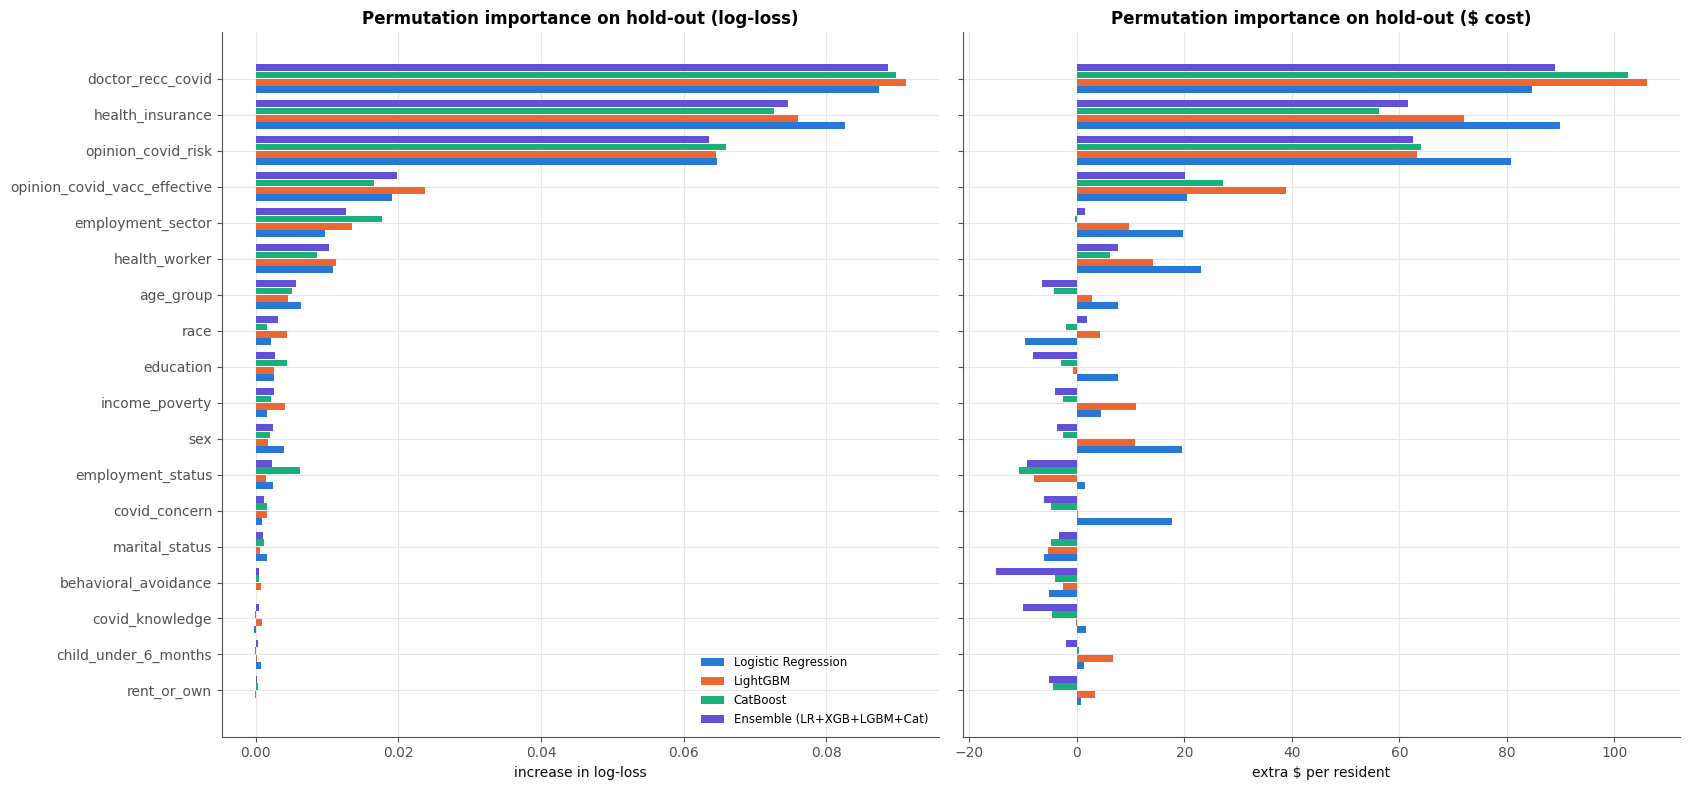

In [7]:
# Permutation importance on the hold-out set (models trained on the development set only)
P_HOLD = pd.Series(MAIN.p_unvacc(X_hold), index=X_hold.index)          # true person's risk, NOT the permuted one
T_HOLD = pd.Series(MAIN.personal_threshold(X_hold), index=X_hold.index)

def cost_scorer(estimator, X, y):
    # Negative $ per resident with personal thresholds (risk looked up by row index, so it is never permuted).
    q = estimator.predict_proba(X)[:, 1]
    send = q >= T_HOLD.loc[X.index].to_numpy()
    return -person_costs(np.asarray(y), send, P_HOLD.loc[X.index].to_numpy()).mean()

def logloss_scorer(estimator, X, y):
    return -log_loss(y, estimator.predict_proba(X)[:, 1])

t0 = time.time()
perm = {}
for name in ['Logistic Regression', 'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']:
    for metric, scorer in [('log-loss', logloss_scorer), ('$ cost', cost_scorer)]:
        r = permutation_importance(HOLD_MODELS[name], X_hold, y_hold, scoring=scorer, n_repeats=5,
                                   random_state=RANDOM_STATE, n_jobs=1)
        perm[(name, metric)] = pd.Series(r.importances_mean, index=X_hold.columns)
perm = pd.DataFrame(perm)
print(f'permutation importance done in {time.time() - t0:.0f}s')

fig, axes = plt.subplots(1, 2, figsize=(17, 8), sharey=True)
order = perm[('Ensemble (LR+XGB+LGBM+Cat)', 'log-loss')].sort_values().index[-18:]
for ax, metric, unit in zip(axes, ['log-loss', '$ cost'], ['increase in log-loss', 'extra $ per resident']):
    sub = perm.xs(metric, axis=1, level=1).loc[order]
    y = np.arange(len(order))
    for i, (m, col) in enumerate(zip(sub.columns, [BLUE, ORANGE, AQUA, VIOLET])):
        ax.barh(y + (i - 1.5) * 0.2, sub[m], height=0.19, color=col, label=m)
    ax.set_yticks(y, order); ax.set_xlabel(unit); ax.set_title(f'Permutation importance on hold-out ({metric})')
axes[0].legend(loc='lower right', fontsize=8.5)
plt.tight_layout(); savefig('09_permutation_importance'); plt.show()

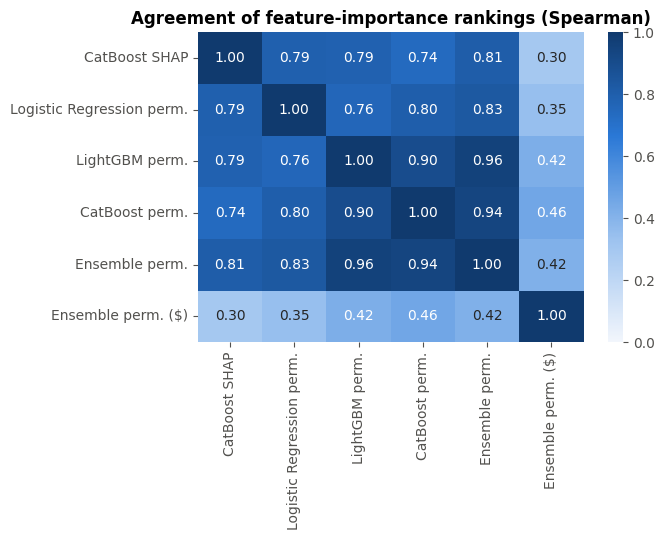

,CatBoost SHAP,Logistic Regression perm.,LightGBM perm.,CatBoost perm.,Ensemble perm.,Ensemble perm. ($)
health_insurance,1.0,2.0,2.0,2.0,2.0,3.0
doctor_recc_covid,2.0,1.0,1.0,1.0,1.0,1.0
opinion_covid_risk,3.0,3.0,3.0,3.0,3.0,2.0
opinion_covid_vacc_effective,4.0,4.0,4.0,5.0,4.0,4.0
employment_sector,5.0,6.0,5.0,4.0,5.0,7.0
covid_knowledge,6.0,25.0,14.0,22.0,16.0,27.0
health_worker,7.0,5.0,6.0,6.0,6.0,5.0
age_group,8.0,7.0,7.0,8.0,7.0,23.0
race,9.0,12.0,8.0,12.0,8.0,6.0
sex,10.0,8.0,11.0,11.0,11.0,16.0


In [8]:
# Do the models agree on what matters? Rank correlation of importances across models
rank_cmp = pd.DataFrame({
    'CatBoost SHAP': pd.Series(np.abs(sv).mean(axis=0), index=Xf.columns).reindex(FEATURES),
    **{f'{m.split(" (")[0]} perm.': perm[(m, 'log-loss')].reindex(FEATURES) for m in
       ['Logistic Regression', 'LightGBM', 'CatBoost', 'Ensemble (LR+XGB+LGBM+Cat)']},
    'Ensemble perm. ($)': perm[('Ensemble (LR+XGB+LGBM+Cat)', '$ cost')].reindex(FEATURES),
})
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(rank_cmp.corr(method='spearman'), annot=True, fmt='.2f', cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax)
ax.set_title('Agreement of feature-importance rankings (Spearman)'); plt.tight_layout(); savefig('09_importance_agreement'); plt.show()
rank_cmp.rank(ascending=False).sort_values('CatBoost SHAP').head(10)

**What the explanations tell us**
* **All methods agree on the four main drivers** – doctor's recommendation, health insurance, perceived COVID risk and belief in vaccine effectiveness –
  followed by health worker / employment sector and age. Disagreements only concern weak features (e.g. `covid_knowledge`,
  `opinion_covid_sick_from_vacc`) whose permutation importance is close to zero.
* **Directions** (SHAP dependence, odds ratios): a doctor's recommendation adds ≈1.6 log-odds (≈5× the odds); acceptance rises steadily with perceived
  risk and jumps at "very effective"; health workers and older people accept more.
* **Health insurance** is important largely because of *non-response*: people who skipped the question are much less likely to accept (grey cloud on the
  far left of the beeswarm, 'NaN' column in the dependence plot). This confirms the EDA and the value of missing-aware pre-processing.
* **Cost-based permutation importance** expresses importance in dollars: scrambling the doctor's recommendation would cost the town ≈\$85–105 per resident,
  health insurance and perceived risk ≈\$65–95; demographic features are worth only a few dollars (small negative values are noise).
* Odds ratios for **rare categories** (e.g. `employment_sector = technology`, n ≈ 48) are large but uncertain – big effects estimated on small groups
  should not be over-interpreted.
* Being *worried about side effects* is associated with slightly **higher** acceptance – worried respondents are also more concerned about COVID in general.
  xAI explains what the model learned from correlations; it does not prove causation.

In [9]:
# ---- Conclusions with the numbers of this run ----
first = FINAL.iloc[0]
cost_first = exp_costs.iloc[0]
nobody, everybody = exp_costs['(reference) send to nobody'], exp_costs['(reference) send to everybody']
captured = hold_table.loc[first['model'], '% saving captured [personal thr]']
auc_range = hold_table.drop('Baseline: prior only')['ROC-AUC']
display(Markdown(f'''
## 10. Conclusions
1. The real target is the **expected town cost**. Deriving it shows that the optimal decision is a **personal threshold**
   1500 / (1500 + 41000 · p · VE) on the acceptance probability, where p comes from a researched hospitalisation-risk model (notebook 01).
2. **Keeping the information in missing answers** was the biggest pre-processing gain (≈\\$45 per resident, ≈+0.025 ROC-AUC, notebook 04).
3. Tuned gradient-boosting models, logistic regression and their **soft-voting ensemble** are all close (hold-out ROC-AUC {auc_range.min():.3f}–{auc_range.max():.3f});
   the differences between good models are within the noise (notebooks 06–07).
4. The **decision layer matters more than the algorithm**: personal thresholds save ≈\\$100 per resident compared with a 0.5 threshold and
   ≈\\$70 compared with the best single threshold, under 4 of the 5 hospitalisation scenarios (notebooks 06–07).
5. Our first submission (**{first['candidate']}**) is expected to cost the test town ≈\\${cost_first / 1e6:,.2f} M, versus ≈\\${nobody / 1e6:,.2f} M if no
   vaccines were posted and ≈\\${everybody / 1e6:,.2f} M if everybody got one – a saving of ≈\\${(nobody - cost_first) / 1e6:,.1f} M. On the hold-out set the
   same model captured {captured:.0f} % of the saving that perfect knowledge would give.
'''))


## 10. Conclusions
1. The real target is the **expected town cost**. Deriving it shows that the optimal decision is a **personal threshold**
   1500 / (1500 + 41000 · p · VE) on the acceptance probability, where p comes from a researched hospitalisation-risk model (notebook 01).
2. **Keeping the information in missing answers** was the biggest pre-processing gain (≈\$45 per resident, ≈+0.025 ROC-AUC, notebook 04).
3. Tuned gradient-boosting models, logistic regression and their **soft-voting ensemble** are all close (hold-out ROC-AUC 0.856–0.867);
   the differences between good models are within the noise (notebooks 06–07).
4. The **decision layer matters more than the algorithm**: personal thresholds save ≈\$100 per resident compared with a 0.5 threshold and
   ≈\$70 compared with the best single threshold, under 4 of the 5 hospitalisation scenarios (notebooks 06–07).
5. Our first submission (**XGBoost | personal thr**) is expected to cost the test town ≈\$14.93 M, versus ≈\$18.53 M if no
   vaccines were posted and ≈\$17.96 M if everybody got one – a saving of ≈\$3.6 M. On the hold-out set the
   same model captured 67 % of the saving that perfect knowledge would give.


### Limitations and next steps
* **Hospitalisation probabilities are assumptions**, not data. We mitigated this with five scenarios; a deeper approach would fit a hospitalisation
  model on an external dataset (e.g. COVID-NET / CDC case surveillance) and propagate its uncertainty.
* The acceptance model is limited by the information in the survey (all models plateau at ROC-AUC ≈ 0.86–0.87). More gains would need new
  information (e.g. prior vaccination history), not a more complex algorithm.
* Vaccine effectiveness is treated as a single number; in reality it varies with age and immune status.
* The ensemble weights are equal; optimising them (or stacking) on out-of-fold predictions might add a little, at the risk of over-fitting a small dataset.

In [10]:
display(Markdown(f'''
### Summary for a non-specialist audience
> **The question:** our town must post COVID vaccines to people's homes. A dose that is refused is wasted (\\$1 500), but anybody who wanted a vaccine
> and did not get one must be paid \\$1 500, and unvaccinated people are more likely to end up in hospital (\\$41 000 per stay).
>
> **What we did:** we trained a computer model on a survey of 4 756 people to estimate how likely each person is to accept a vaccine. The most
> telling signs are whether their **doctor recommended it**, whether they **believe the vaccine works**, and how **risky they think COVID is**.
> We then combined this with medical research on **who is likely to be hospitalised** (mainly older people and people with chronic illnesses).
>
> **The key idea:** every person has a "bar" set by how dangerous COVID is for them. If the model's chance that they say yes is above their bar,
> we post them a vaccine. For an older person with health problems the bar is about 10–20 %; for a healthy 25-year-old it is about 75 %.
>
> **Result:** compared with sending vaccines to nobody, our approach is expected to save the test town **about \\${(nobody - cost_first) / 1e6:,.1f} million**.
'''))


### Summary for a non-specialist audience
> **The question:** our town must post COVID vaccines to people's homes. A dose that is refused is wasted (\$1 500), but anybody who wanted a vaccine
> and did not get one must be paid \$1 500, and unvaccinated people are more likely to end up in hospital (\$41 000 per stay).
>
> **What we did:** we trained a computer model on a survey of 4 756 people to estimate how likely each person is to accept a vaccine. The most
> telling signs are whether their **doctor recommended it**, whether they **believe the vaccine works**, and how **risky they think COVID is**.
> We then combined this with medical research on **who is likely to be hospitalised** (mainly older people and people with chronic illnesses).
>
> **The key idea:** every person has a "bar" set by how dangerous COVID is for them. If the model's chance that they say yes is above their bar,
> we post them a vaccine. For an older person with health problems the bar is about 10–20 %; for a healthy 25-year-old it is about 75 %.
>
> **Result:** compared with sending vaccines to nobody, our approach is expected to save the test town **about \$3.6 million**.
